ML environment ready
(442, 11)
X shape: (442, 10)
Y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
(353, 10)
(89, 10)
Slope: 998.5776891375592
Intercept: 152.00335421448167
First 5 predictions: [145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]


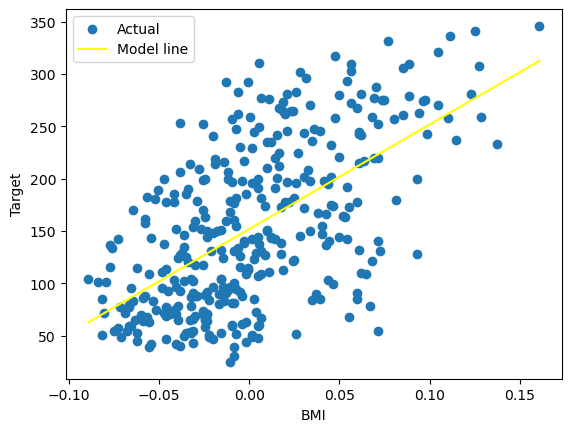

Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]
0.44 0.12
Prediction at x=6: 2.76
ElasticNet R2: 0.459


In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
print("ML environment ready")
from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print(df.shape)
df.head()
X = df.drop(columns=["target"])
y = df["target"]
print("X shape:", X.shape)
print("Y shape:", y.shape)
print(X.head())
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(   
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape) 
print(X_test.shape)
from sklearn.linear_model import LinearRegression 
X1 = X[["bmi"]] 
Xtr, Xte, ytr, yte = train_test_split(
X1, y, test_size=0.2, random_state=42
)
simple = LinearRegression() 
simple.fit(Xtr, ytr)
pred = simple.predict(Xte) 
print("Slope:", simple.coef_[0]) 
print("Intercept:", simple.intercept_) 
print("First 5 predictions:", pred[:5])   
pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
Xtr["bmi"].values[order],
pred_train[order],
color="yellow", label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Target")
plt.legend()
plt.show()
multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_) 
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])
import numpy as np
x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)

m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
db = (-2/len(x))*np.sum(y_demo-yhat)
m -= lr*dm
b -= lr*db
print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2)) 
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score
models = {
"Ridge": Ridge(alpha=1.0), 
"Lasso": Lasso(alpha=0.1, max_iter=10000),
"ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}
for name, alg in models.items():
 pipe = make_pipeline(StandardScaler(), alg)
pipe.fit(X_train, y_train)
p = pipe.predict(X_test)    
print(name, "R2:", round(r2_score(y_test,p),3))

In [10]:
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit() 
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        10:31:17   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

In [10]:
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit() 
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        10:31:17   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

In [10]:
import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit() 
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        10:31:17   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             3834.
Df Residuals:                     342   BIC:                             3877.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        151.3456      2.902     52.155      0.0

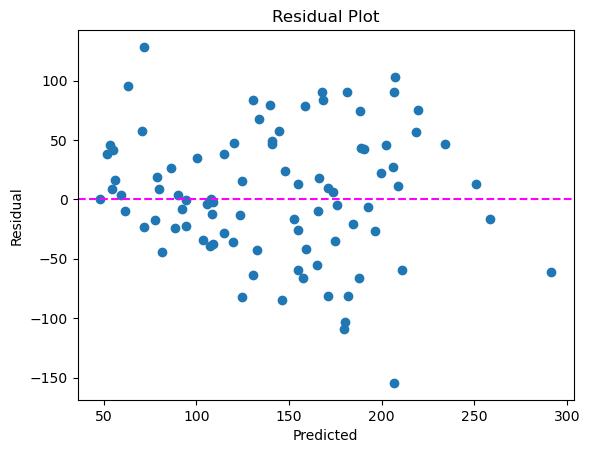

In [12]:
residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="magenta", linestyle="--") 
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

ML environment ready
(442, 11)
X shape: (442, 10)
y shape: (442,)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  
(353, 10)
(89, 10)
Slope: 998.5776891375592
Intercept: 152.00335421448167
First 5 predictions: [145.80622687 188.85739048 147.95878505 203.92529774 131.8145987 ]


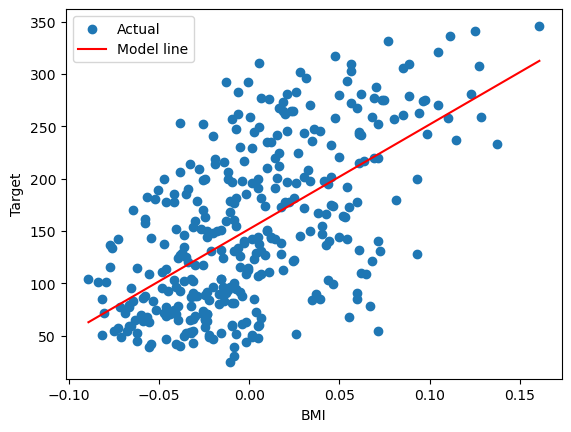

Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept: 151.34560453985995
First predictions: [139.5475584  179.51720835 134.03875572 291.41702925 123.78965872]
[144.31652431 187.37853935 146.40224431 203.1205058  130.93222915]
MSE: 2900.1936284934804
2.0 0.02
Prediction at x=6: 11.99
Ridge R2: 0.454
Lasso R2: 0.456
ElasticNet R2: 0.459
                            OLS Regression Results                            
Dep. Variable:                 target   R-squared:                       0.528
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     38.25
Date:                Wed, 18 Nov 2026   Prob (F-statistic):           5.41e-50
Time:                        12:00:32   Log-Likelihood:                -1906.1
No. Observations:                 353   AIC:                             38

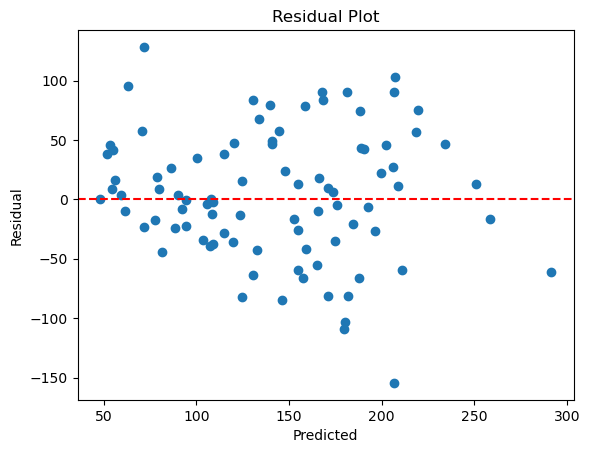

1 3854.11265207582 4061.8259284949268
2 3849.333133411179 4085.025480871632
5 3823.763813306944 4085.845566850978
10 3724.6126872010464 4315.533060005422
MAE: 42.79409467959994
MSE: 2900.1936284934804
RMSE: 53.85344583676592
R2: 0.4526027629719197


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("ML environment ready")

from sklearn.datasets import load_diabetes
dataset = load_diabetes(as_frame=True)
df = dataset.frame
print(df.shape)
df.head()

X = df.drop(columns=["target"])
y = df["target"]
print("X shape:", X.shape)
print("y shape:", y.shape)
print(X.head())

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape)
print(X_test.shape)

from sklearn.linear_model import LinearRegression
X1 = X[["bmi"]]
Xtr, Xte, ytr, yte = train_test_split(
    X1, y, test_size=0.2, random_state=42
)
simple = LinearRegression()
simple.fit(Xtr, ytr)
pred = simple.predict(Xte)
print("Slope:", simple.coef_[0])
print("Intercept:", simple.intercept_)
print("First 5 predictions:", pred[:5])

pred_train = simple.predict(Xtr)
order = np.argsort(Xtr["bmi"].values)
plt.scatter(Xtr["bmi"], ytr, label="Actual")
plt.plot(
    Xtr["bmi"].values[order],
    pred_train[order],
    color="red", label="Model line"
)
plt.xlabel("BMI")
plt.ylabel("Target")
plt.legend()
plt.show()

multiple = LinearRegression()
multiple.fit(X_train, y_train)
pred_multi = multiple.predict(X_test)
print("Coefficients:", multiple.coef_)
print("Intercept:", multiple.intercept_)
print("First predictions:", pred_multi[:5])

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly.fit(X_train[["bmi"]], y_train)
poly_pred = poly.predict(X_test[["bmi"]])
print(poly_pred[:5])

from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, pred_multi)
print("MSE:", mse)

x = np.array([1,2,3,4,5], dtype=float)
y_demo = np.array([2,4,6,8,10], dtype=float)
m, b = 0.0, 0.0
lr = 0.01
for epoch in range(1000):
    yhat = m*x + b
    dm = (-2/len(x))*np.sum(x*(y_demo-yhat))
    db = (-2/len(x))*np.sum(y_demo-yhat)
    m -= lr*dm
    b -= lr*db
print(round(m, 2), round(b, 2))
print("Prediction at x=6:", round(m*6+b, 2))

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score
models = {
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "ElasticNet": ElasticNet(alpha=0.1, max_iter=10000)
}
for name, alg in models.items():
    pipe = make_pipeline(StandardScaler(), alg)
    pipe.fit(X_train, y_train)
    p = pipe.predict(X_test)
    print(name, "R2:", round(r2_score(y_test,p),3))

import statsmodels.api as sm
X_sm = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_sm).fit()
print(ols.summary())

residuals = y_test - pred_multi
plt.scatter(pred_multi, residuals)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()

from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
for degree in [1, 2, 5, 10]:
    model = make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )
    model.fit(X_train[["bmi"]], y_train)
    tr = model.predict(X_train[["bmi"]])
    te = model.predict(X_test[["bmi"]])
    print(degree,
          mean_squared_error(y_train,tr),
          mean_squared_error(y_test,te))

# 15. Bias–Variance trade-off
# Compare train and test errors using the degree loop from the previous code.
# Low train error + high test error: possible high variance.
# High train error + high test error: possible high bias.

# 16. Regression metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, pred_multi)
mse = mean_squared_error(y_test, pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred_multi)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2)